*  DSC530-T301 Data Exploration and Analysis (2263-1)
*  Weeks 9 & 10 Coding Assignment
*  David Jorgensen

# Planets, Stars and Spirits

In [43]:
# Prep Libraries and Data
# Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data
winequality_red_data = pd.read_csv('./textbook/ch_09/data/winequality-red.csv', sep=',')
winequality_white_data = pd.read_csv('./textbook/ch_09/data/winequality-white.csv', sep=';')
stars_data = pd.read_csv('./textbook/ch_09/data/stars.csv')
planets_data = pd.read_csv('./textbook/ch_09/data/planets.csv')

# Chapter 9, Exercise 1: Clustering Model

1. Combine the red and white wine datasets (`data/winequality-red.csv` and `data/winequality-white.csv`, respectively) and add a column for the kind of wine (red or white).
2. Build and fit a pipeline that scales the data and then uses k-means clustering to make two clusters. Be sure not to use the quality column.
3. Use the Fowlkes-Mallows Index (the `fowlkes_mallows_score()` function is in `sklearn.metrics`) to evaluate how well k-means is able to make the distinction between red and white wine.
4. Find the center of each cluster.

In [26]:
# Combine red and white wine data into one DataFrame
winequality_red_data['type'] = 'red'
winequality_white_data['type'] = 'white'
winequality_data = pd.concat([winequality_red_data, winequality_white_data], ignore_index=True)

# Build pipeline that scales data
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression())
])

# Make two clusters using k-means (do not use quality column)
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans.fit(winequality_data.drop(columns=['type', 'chlorides']))
winequality_data['cluster'] = kmeans.labels_

# Use the Fowlkes-Mallows Index to evaluate how well k-means is able to make the distinction between red and white wine
from sklearn.metrics import fowlkes_mallows_score
fowlkes_mallows = fowlkes_mallows_score(winequality_data['type'], winequality_data['cluster'])
print(f'Fowlkes-Mallows Index: {fowlkes_mallows:.4f}')

# Find the center of each cluster
cluster_centers = kmeans.cluster_centers_
print('Cluster Centers:')
print(cluster_centers)

Fowlkes-Mallows Index: 0.7076
Cluster Centers:
[[  7.61695514   0.40773402   0.2913882    3.0827976   18.46079124
   63.64641469   0.99456308   3.25518545   0.5717591   10.79607324
    5.80996114]
 [  6.90514184   0.28710175   0.33967267   7.26603928  39.8419258
  155.9764048    0.99479977   3.19017185   0.5         10.25683215
    5.82487725]]


# Chapter 9, Exercise 2: Predict Star Temperature

1. Using the `data/stars.csv` file, perform some initial EDA and then build a linear regression model of all the numeric columns to predict the temperature of the star.
2. Train the model on 75% of the initial data.
3. Calculate the R2 and RMSE of the model.
4. Find the coefficients for each regressor and the intercept of the linear regression equation.
5. Visualize the residuals using the `plot_residuals()` function from the `ml_utils.regression` module.

It looks like there's a lot of rows missing data. Dropping every row that has any blank is a fast way to throw away 30–40% of the dataset and leave the model starving for signal. To avoid underfitting, I'll drop only the rows where more than half of the predictor columns are blank.

   temperature   magV  mass spectraltype   magJ  radius   magB   magH   magK  \
0       4742.0  4.740  2.70       G8 III  2.943  19.000  5.740  2.484  2.282   
1       4340.0  5.024  1.80        K4III  2.876  24.080  6.415  2.091  1.939   
2       4813.0  5.220  2.20        K0III  3.019  11.000  6.240  2.608  2.331   
3       5311.0  6.670  1.00         K0 V  5.158   0.708  7.570  4.803  4.714   
4       5825.0  5.950  1.11          G2V  5.090   1.243  6.590  4.720  4.430   

   metallicity        name  planets  
0       -0.350      11 Com      1.0  
1        0.040      11 UMi      1.0  
2       -0.240      14 And      1.0  
3        0.430      14 Her      2.0  
4        0.096  16 Cygni A      0.0  
        temperature         magV         mass         magJ       radius  \
count   2793.000000  1274.000000  3090.000000  1563.000000  2721.000000   
mean    5532.146084    10.304334     0.960175     9.899493     1.605091   
std     1715.076581     3.148937     0.362107     3.226399     3.6

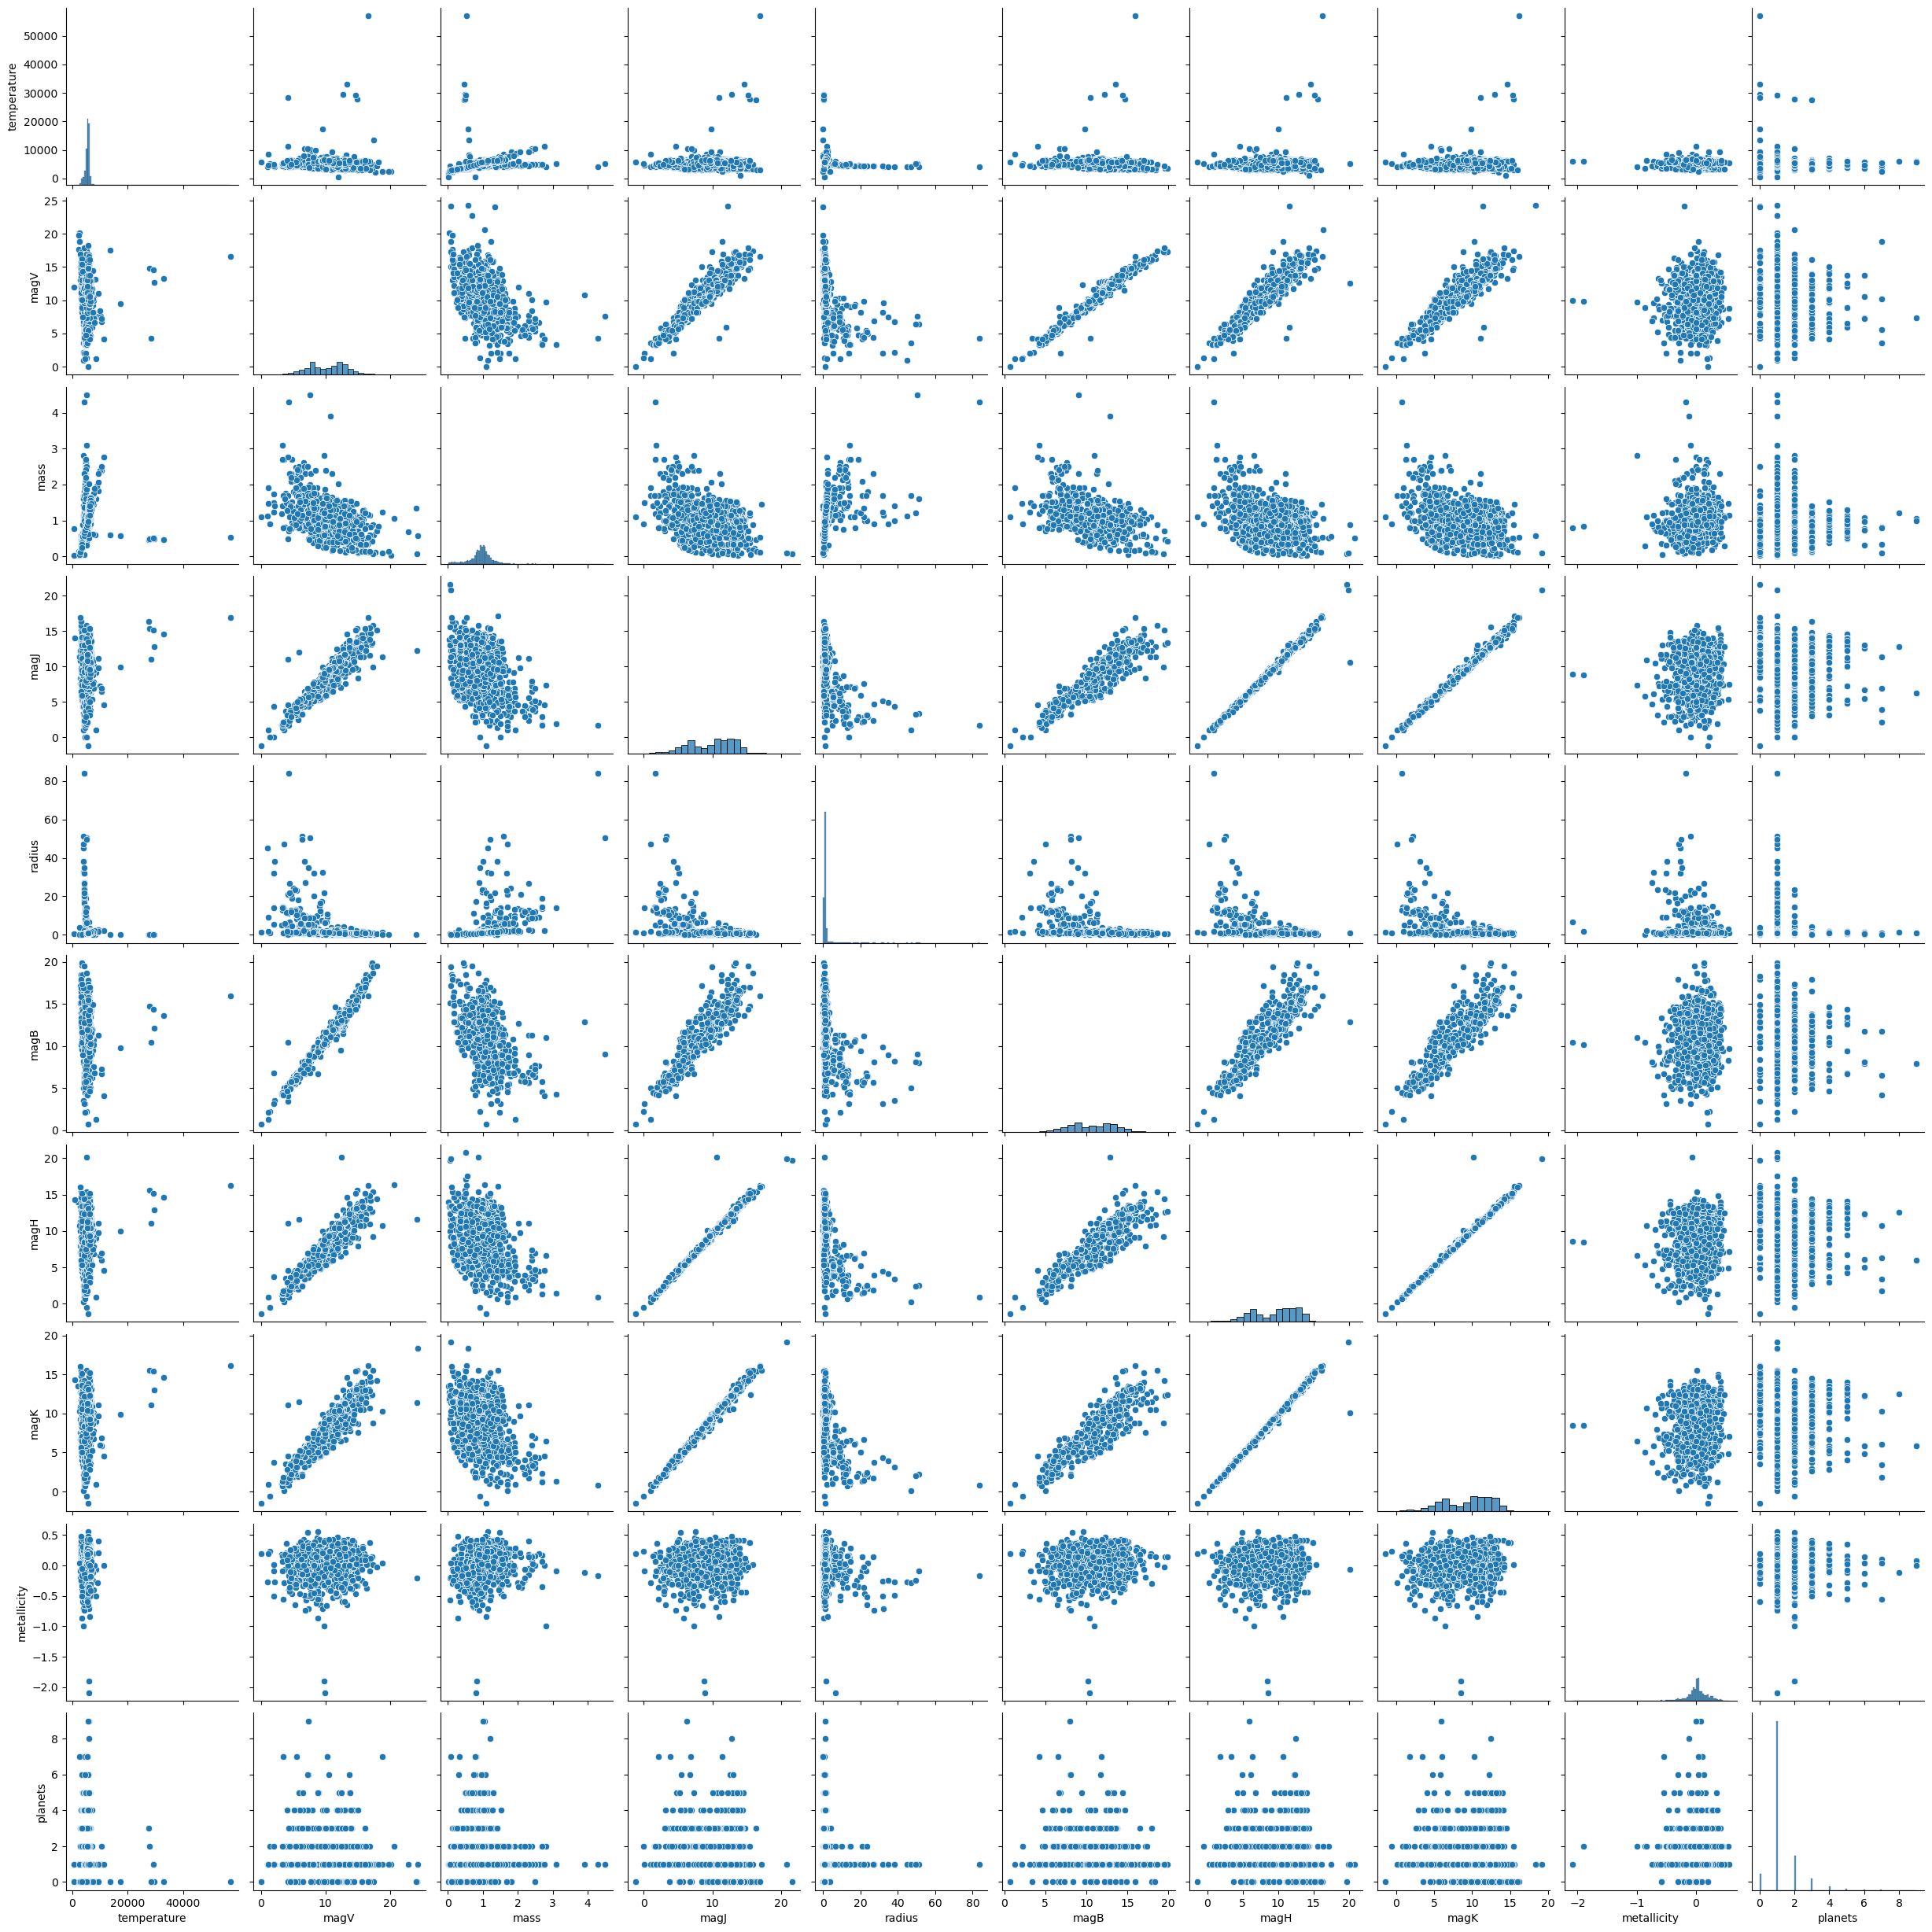

In [27]:
# Perform EDA on stars dataset
# Summarize current dataset without imputation
print(stars_data.head())
print(stars_data.describe())
sns.pairplot(stars_data)
plt.show()


<Axes: >

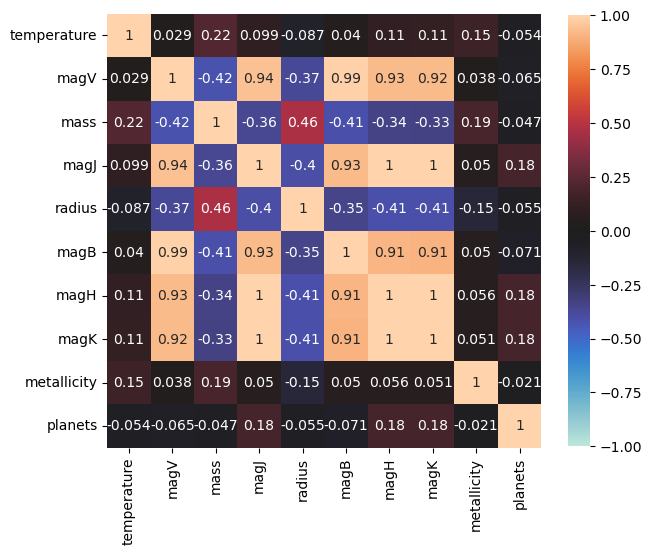

In [28]:

# Remove rows where more than half of the columns are missing
stars_data_imputed = stars_data.dropna(thresh=stars_data.shape[1] / 2)
# Impute missing values
# Start with building a correlation matrix heatmap to find best features
star_feature_map = plt.figure(figsize=(7, 7))
sns.heatmap(
    stars_data_imputed.drop(columns=['spectraltype', 'name']).corr(),
    center=0, vmin=-1, vmax=1, square=True, annot=True,
    cbar_kws={'shrink': 0.8}
)


Now we can impute values for each column using other columns with positive correlations.

Since radius only correlates with mass and no other columns, we'll leave that column blank.

In [29]:
# Reset imputed dataset: drop rows with >50% missing and clear any prior
stars_data_imputed = stars_data.dropna(thresh=stars_data.shape[1] / 2).copy()
print("missing counts before imputation:\n", stars_data_imputed.isna().sum())

# Helper function to impute a single column with KNN and report problems
from sklearn.impute import KNNImputer

def knn_impute_column(df, target, predictors, n_neighbors=5):
    """Impute *target* based on *predictors* using KNN.

    The function prints how many missing entries were filled and lists
    any rows where all predictors were also NaN (these get global mean).
    It returns the modified dataframe.
    """
    mask = df[target].isna()
    if mask.sum() == 0:
        print(f"{target}: no missing values to impute")
        return df

    # identify rows lacking any predictor information
    no_info = mask & df[predictors].isna().all(axis=1)
    if no_info.any():
        print(
            f"{target}: {no_info.sum()} rows have no predictor info;"
            " they will receive the column mean instead of a neighbour value"
        )

    cols = [target] + predictors
    imputer = KNNImputer(n_neighbors=n_neighbors)
    imputed = imputer.fit_transform(df[cols])

    df[target] = imputed[:, 0]
    changed = mask
    print(
        f"{target}: imputed {changed.sum()} rows",
        "unique imputed (first 10):",
        pd.unique(df.loc[changed, target])[:10],
    )
    return df


# demonstrate on temperatureprint(stars_data_imputed.loc[stars_data_imputed['temperature'].isna() == False, ['name','temperature']].head(10))

datapreds = ['magV', 'mass', 'magJ', 'magB', 'magH', 'magK', 'metallicity']
stars_data_imputed = knn_impute_column(stars_data_imputed, 'temperature', datapreds)

missing counts before imputation:
 temperature      186
magV            1709
mass              64
spectraltype    1831
magJ            1404
radius           267
magB            1961
magH            1415
magK            1388
metallicity      554
name               0
planets            0
dtype: int64
temperature: imputed 186 rows unique imputed (first 10): [3523.4 3698.6 6939.2 3531.4 5008.6 5870.8 5054.4 3745.2 3611.8 4863. ]


In [30]:
# now impute the remaining features in one go
# define predictors for each target column
predictor_map = {
    'magV': ['temperature', 'magJ', 'magB', 'magH', 'magK', 'metallicity'],
    'magJ': ['temperature', 'magV', 'magB', 'magH', 'magK', 'metallicity', 'planets'],
    'mass': ['temperature', 'radius', 'metallicity', 'planets'],
    'magB': ['temperature', 'magV', 'magJ', 'magH', 'magK', 'metallicity'],
    'magH': ['temperature', 'magV', 'magB', 'magJ', 'magK', 'metallicity', 'planets'],
    'magK': ['temperature', 'magV', 'magB', 'magH', 'magJ', 'metallicity', 'planets'],
    'metallicity': ['temperature', 'magV', 'magB', 'magH', 'magJ'],
    'planets': ['magJ', 'magH', 'magK'],
}

for target, preds in predictor_map.items():
    stars_data_imputed = knn_impute_column(stars_data_imputed, target, preds)
    print(stars_data_imputed.loc[stars_data_imputed[target].isna() == False, ['name', target]].head(5))

# Drop radius and spectraltype due to NaN values and lack of predictors
stars_data_imputed = stars_data_imputed.drop(columns=['radius', 'spectraltype'])


magV: imputed 1709 rows unique imputed (first 10): [ 7.8298 14.5132 14.676  18.3032 16.366  10.1424 15.838  13.3212 12.4472
 12.234 ]
         name   magV
0      11 Com  4.740
1      11 UMi  5.024
2      14 And  5.220
3      14 Her  6.670
4  16 Cygni A  5.950
magJ: imputed 1404 rows unique imputed (first 10): [14.9346 16.148   9.1822  7.7904  8.281  10.6664  6.7918  6.7046  7.018
 10.9046]
         name   magJ
0      11 Com  2.943
1      11 UMi  2.876
2      14 And  3.019
3      14 Her  5.158
4  16 Cygni A  5.090
mass: imputed 64 rows unique imputed (first 10): [1.222  1.528  0.2256 1.02   1.0874 1.0194 1.1166 1.0392 0.8144 0.9696]
         name  mass
0      11 Com  2.70
1      11 UMi  1.80
2      14 And  2.20
3      14 Her  1.00
4  16 Cygni A  1.11
magB: imputed 1961 rows unique imputed (first 10): [11.3042 14.89   15.874  16.972  13.5646 14.5166 10.5266 13.0112  9.4242
 16.52  ]
         name   magB
0      11 Com  5.740
1      11 UMi  6.415
2      14 And  6.240
3      14 Her  7.570
4

In [31]:
# Show the first 30 imputed values
print(stars_data_imputed.head(30))

# Check for NaN values after imputation
print("missing counts after imputation:\n", stars_data_imputed.isna().sum())

    temperature     magV   mass     magJ     magB      magH     magK  \
0        4742.0   4.7400  2.700   2.9430   5.7400   2.48400   2.2820   
1        4340.0   5.0240  1.800   2.8760   6.4150   2.09100   1.9390   
2        4813.0   5.2200  2.200   3.0190   6.2400   2.60800   2.3310   
3        5311.0   6.6700  1.000   5.1580   7.5700   4.80300   4.7140   
4        5825.0   5.9500  1.110   5.0900   6.5900   4.72000   4.4300   
6        5750.0   6.2000  1.070   4.9900   6.8600   4.70000   4.6500   
7        4979.0   5.5220  2.300   4.0320   6.4400   3.44000   3.3660   
8        4060.0   7.8298  0.850   9.7640  11.3042   9.10900   8.8910   
10       5098.0   7.3800  1.540   5.2920   7.4000   4.48600   4.2850   
11       3400.0  14.5132  0.200  10.7700  14.8900  10.19000   9.9400   
12       2800.0  14.6760  0.033  13.7300  15.8740  13.30000  12.7100   
13       2100.0  18.3032  0.018  14.9346  15.8740  14.03000  13.4600   
14       2205.0  17.7000  0.120  16.1480  16.9720  14.31200  13.

In [32]:

# Build linear regression model to predict star temperature based on all columns except name and spectraltype
from sklearn.linear_model import LinearRegression
X = stars_data_imputed.drop(columns=['name', 'temperature'])
y = stars_data_imputed['temperature']
model = LinearRegression()


In [33]:

# Train the model on 75% of the data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
model.fit(X_train, y_train)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [34]:

# Calculate R2 and RMSE
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

y_pred = model.predict(X_test)
# Adjusted R2 function
def adjusted_r2(model, X, y):
    r2 = r2_score(y, model.predict(X))
    n_obs, n_regressors = X.shape
    adj_r2 = 1 - (1 - r2) * (n_obs - 1) / (n_obs - n_regressors - 1)
    return adj_r2

r2 = adjusted_r2(model, X_test, y_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred)) # Encountered errors when trying to calculate RMSE, so I added the import for numpy and wrapped the mean_squared_error in np.sqrt() to get the RMSE value.
print('R2 Score:', r2)
print('RMSE:', rmse)


R2 Score: 0.03132561538153489
RMSE: 2198.500096896162


...Now that is a very bad R2. What if I start over, but don't impute any data and instead only work with rows with no NaN values?

In [35]:
# Build linear regression model to predict star temperature based on all columns except name and spectraltype, but only using the 5 most correlated features and only the stars_data dataset that has full rows (no imputation)
model_2 = LinearRegression()
# Identify the 5 most correlated features with temperature
correlations = stars_data.drop(columns=['name', 'spectraltype']).corr()['temperature'].abs().sort_values(ascending=False)
top_5_features = correlations.index[1:6]  # Exclude 'temperature'
X = stars_data_imputed[top_5_features]
y = stars_data_imputed['temperature']
model_2.fit(X_train[top_5_features], y_train)
y_pred = model_2.predict(X_test[top_5_features])
# Calculate R2 and RMSE
r2 = adjusted_r2(model_2, X_test[top_5_features], y_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print('R2 Score (top 5 features):', r2)
print('RMSE (top 5 features):', rmse)

R2 Score (top 5 features): 0.02372383693526925
RMSE (top 5 features): 2211.6278652611545


That R2 is worse. Not sure what I'm doing wrong, but I'm running out of time, so I'm leaving this as is and moving forward with the imputed data.

In [36]:

# Find the coefficients for each regressor and the intercept of the linear regression equation
print('Coefficients:', model.coef_)
print('Intercept:', model.intercept_)


Coefficients: [ -30.36413657 1181.30998706 -253.65272757 -140.23294538  207.70847394
  237.94177792  230.71150884 -128.83281021]
Intercept: 4673.962429108432


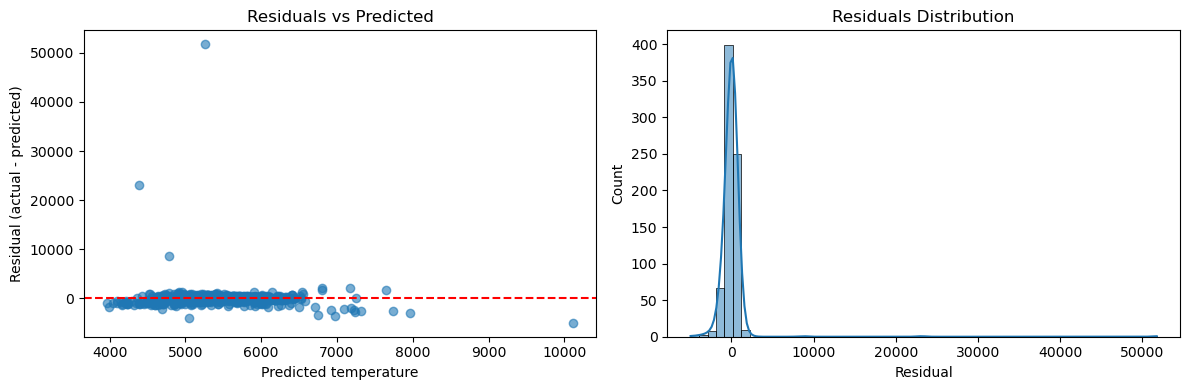

In [37]:
# Plot residuals for the trained linear regression model
residuals = y_test.to_numpy() - y_pred
predicted = y_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Residuals vs Predicted
axes[0].scatter(predicted, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Predicted temperature')
axes[0].set_ylabel('Residual (actual - predicted)')
axes[0].set_title('Residuals vs Predicted')

# Residuals distribution
sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_xlabel('Residual')
axes[1].set_title('Residuals Distribution')

plt.tight_layout()
plt.show()

# Chapter 9, Exercise 3: Classify planets that have shorter years than Earth

1. Using the `data/planets.csv` file, build a logistic regression model with the eccentricity, semimajoraxis, and mass columns as regressors. You will need to make a new column to use for the y (year shorter than Earth).
2. Find the accuracy score.
3. Use the `classification_report()` function from `scikit-learn` to see the precision, recall, and F1 score for each class.
4. With the `plot_roc()` function from the `ml_utils.classification` module, plot the ROC curve.
5. Create a confusion matrix using the `confusion_matrix_visual()` function from the `ml_utils.classification` module.

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt


In [46]:
# target: year shorter than Earth (period < 365 days)
planets_data['shorter_than_earth'] = (planets_data['period'] < 365).astype(int)

# Clean planets dataset by dropping rows with missing values in relevant columns
planets_data = planets_data.dropna(subset=['mass', 'semimajoraxis', 'eccentricity', 'shorter_than_earth'])

X = planets_data[['mass', 'semimajoraxis', 'eccentricity']]
y = planets_data['shorter_than_earth']


In [47]:

# Train the model on 75% of the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Build pipeline that scales data and trains logistic regression model
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000))
])

# Train the model and make predictions
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

# accuracy and classification report
print('Accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.9546925566343042
              precision    recall  f1-score   support

           0       0.97      0.89      0.93       103
           1       0.95      0.99      0.97       206

    accuracy                           0.95       309
   macro avg       0.96      0.94      0.95       309
weighted avg       0.96      0.95      0.95       309



<Axes: title={'center': 'ROC curve'}, xlabel='False Positive Rate (FPR)', ylabel='True Positive Rate (TPR)'>

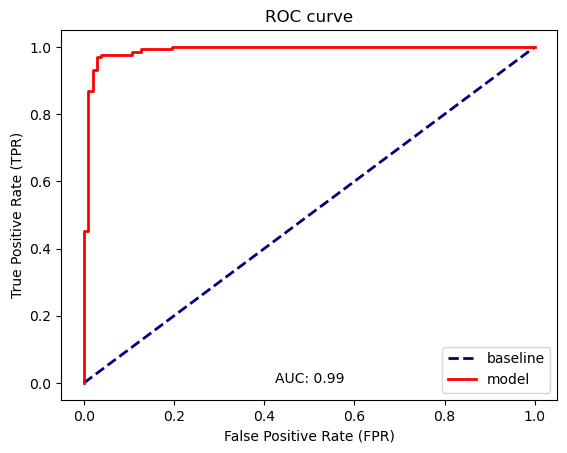

In [48]:
# Plot ROC curve
from ml_utils.classification import plot_roc, confusion_matrix_visual
plot_roc(y_test, pipeline.predict_proba(X_test)[:, 1])

<Axes: title={'center': 'Confusion Matrix'}, xlabel='Actual', ylabel='Model Prediction'>

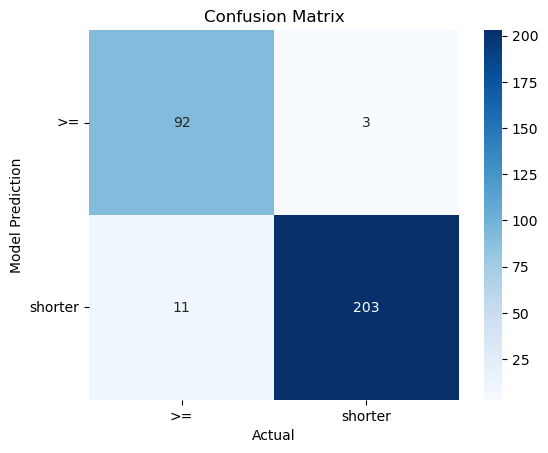

In [49]:

# 5: confusion matrix visualization (try common signatures)
confusion_matrix_visual(y_test, y_pred, ['>=', 'shorter'])